<a href="https://colab.research.google.com/github/DMazaMa/da-inter-25/blob/main/Prueba_intertrimestral_16102025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prueba Intertrimestral

**Nombre:**  
**Apellidos:**  

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 16 de octubre de 2025  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero en el siguiente formulario:  
[https://forms.office.com/e/LFVwu9z6uQ](https://forms.office.com/e/LFVwu9z6uQ)


## Dataset “Life Style Data”

El dataset contiene información sobre hábitos de vida (alimentación, sueño, ejercicio, consumo de tabaco o alcohol, etc.) y medidas de salud (IMC, presión arterial, etc.) para diferentes individuos.

Puedes descargarlo del repositorio de la asignatura y un .txt con la descripción de las variables.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Inicialización de librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función imc(weight, height) que devuelva el índice de masa corporal (IMC), redondeado a dos decimales.



In [ ]:
def imc(weight, height):
    return round(weight / height**2, 2)

imc(70, 1.75)

22.86

b) (0.6 pts) Crea una función saludable(imcValue) que devuelva "Saludable" si el IMC está entre 18.5 y 24.9, "Bajo peso" si es menor de 18.5, o "Sobrepeso" si es mayor de 24.9.

In [ ]:
def saludable(imcValue):
    if imcValue < 18.5:
        return "Bajo peso"
    elif imcValue <= 24.9:
        return "Saludable"
    else:
        return "Sobrepeso"

saludable(22.86)

'Saludable'

c) (0.6 pts) Genera un DataFrame llamado imcData que contenga al menos 10 registros con las siguientes columnas:


*   peso (en kilogramos)

*   altura (en metros)

*   imc (calculado usando la función imc(weight, height) creada anteriormente)

Puedes generar los datos de peso y altura manualmente, mediante listas, o de forma aleatoria utilizando numpy (np.random.uniform o similar).

Añade una cuarta columna llamada categoria, cuyos valores provengan de la función saludable(imcValue).

Muestra las primeras filas del DataFrame resultante y comprueba que los tipos de datos son correctos.

In [ ]:
pesos = [50, 62, 70, 85, 95, 58, 77, 110, 45, 68]
alturas = [1.70, 1.65, 1.80, 1.75, 1.72, 1.60, 1.85, 1.78, 1.68, 1.73]

imcs = []
for i in range(len(pesos)):
    imcs.append(imc(pesos[i], alturas[i]))

imcData = pd.DataFrame()
imcData["peso"] = pesos
imcData["altura"] = alturas
imcData["imc"] = imcs
imcData["categoria"] = imcData["imc"].apply(saludable)

print(imcData.head())
print(imcData.dtypes)

   peso  altura    imc  categoria
0    50    1.70  17.30  Bajo peso
1    62    1.65  22.77  Saludable
2    70    1.80  21.60  Saludable
3    85    1.75  27.76  Sobrepeso
4    95    1.72  32.11  Sobrepeso
peso           int64
altura       float64
imc          float64
categoria     object
dtype: object


d) (0.2 pts) ¿Cómo podrías integrar ambas funciones dentro de una clase llamada HealthTools que calcule el IMC y clasifique automáticamente a partir de listas de pesos y alturas?

In [ ]:
class HealthTools():

    def __init__(self, pesos, alturas):
        self.pesos = pesos
        self.alturas = alturas

    def imc(self, weight, height):
        return round(weight / height**2, 2)

    def saludable(self, imcValue):
        if imcValue < 18.5:
            return "Bajo peso"
        elif imcValue <= 24.9:
            return "Saludable"
        else:
            return "Sobrepeso"

    def clasificar(self):
        resultados = pd.DataFrame()
        resultados["peso"] = self.pesos
        resultados["altura"] = self.alturas
        valores = []
        for i in range(len(self.pesos)):
            valores.append(self.imc(self.pesos[i], self.alturas[i]))
        resultados["imc"] = valores
        resultados["categoria"] = resultados["imc"].apply(self.saludable)
        return resultados

herramientas = HealthTools(pesos, alturas)
herramientas.clasificar()

,peso,altura,imc,categoria
0,50,1.70,17.30,Bajo peso
1,62,1.65,22.77,Saludable
2,70,1.80,21.60,Saludable
3,85,1.75,27.76,Sobrepeso
4,95,1.72,32.11,Sobrepeso
5,58,1.60,22.66,Saludable
6,77,1.85,22.50,Saludable
7,110,1.78,34.72,Sobrepeso
8,45,1.68,15.94,Bajo peso
9,68,1.73,22.72,Saludable


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga el dataset desde el fichero CSV y guárdalo en un DataFrame llamado lifeStyleData. Muestra las 5 primeras filas, el número de filas y columnas.

In [ ]:
lifeStyleData = pd.read_csv("/content/drive/MyDrive/da-inter-25/Final_data.csv")

print(lifeStyleData.head())
print("Número de filas:", lifeStyleData.shape[0])
print("Número de columnas:", lifeStyleData.shape[1])

     Age  Gender  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  \
0  34.91    Male        65.27        1.62   188.58   157.65        69.05   
1  23.37  Female        56.41        1.55   179.43   131.75        73.18   
2  33.20  Female        58.98        1.67   175.04   123.95        54.96   
3  38.69  Female        93.78        1.70   191.21   155.10        50.07   
4  45.09    Male        52.42        1.88   193.58   152.88        70.84   

   Session_Duration (hours)  Calories_Burned Workout_Type  ...  \
0                      1.00          1080.90     Strength  ...   
1                      1.37          1809.91         HIIT  ...   
2                      0.91           802.26       Cardio  ...   
3                      1.10          1450.79         HIIT  ...   
4                      1.08          1166.40     Strength  ...   

   cal_from_macros  pct_carbs  protein_per_kg   pct_HRR  pct_maxHR  \
0          2139.59   0.500432        1.624789  0.741237   0.835985   
1     

b) (0.75 pts) Crea una función describeData(dataFrame) que devuelva para cada columna: tipo de dato, número de valores nulos y porcentaje de nulos.

In [ ]:
def describeData(dataFrame):
    resumen = pd.DataFrame()
    resumen["tipo"] = dataFrame.dtypes
    resumen["nulos"] = dataFrame.isna().sum()
    resumen["porcentaje_nulos"] = round(dataFrame.isna().sum() / len(dataFrame) * 100, 2)
    return resumen

c) (0.75 pts) Usa describeData(lifeStyleData) y comenta brevemente (2–3 líneas) qué variables parecen tener más valores faltantes.

In [ ]:
describeData(lifeStyleData)

,tipo,nulos,porcentaje_nulos
Age,float64,0,0.0
Gender,object,0,0.0
Weight (kg),float64,0,0.0
Height (m),float64,0,0.0
Max_BPM,float64,1,0.0
Avg_BPM,float64,1,0.0
Resting_BPM,float64,0,0.0
Session_Duration (hours),float64,0,0.0
Calories_Burned,float64,0,0.0
Workout_Type,object,0,0.0


d) (0.75 pts) Realiza un gráfico que muestre las correlaciones entre variables numéricas. ¿Hay alguna correlación fuerte o inesperada?

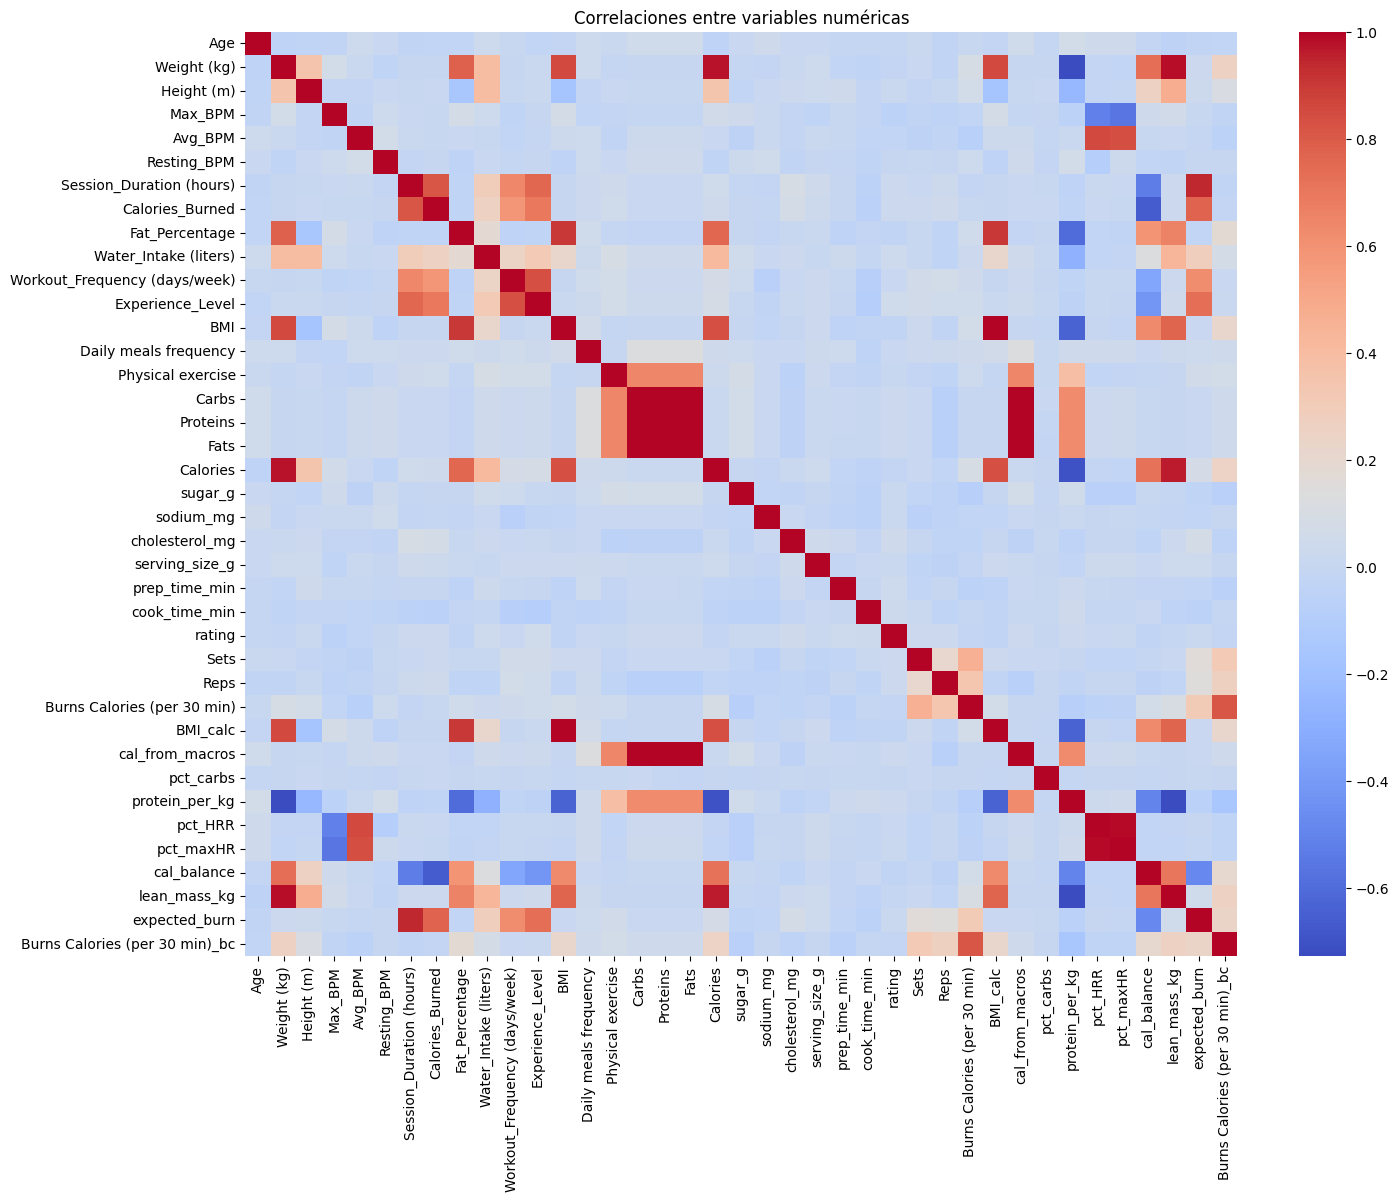

In [ ]:
columnasNumericas = []
for col in lifeStyleData.columns:
    if lifeStyleData[col].dtype != "object":
        columnasNumericas.append(col)

correlaciones = lifeStyleData[columnasNumericas].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlaciones, cmap="coolwarm")
plt.title("Correlaciones entre variables numéricas")
plt.show()

## Ejercicio 3 — Regresión básica (2 puntos)

Queremos predecir una variable de salud continua, por ejemplo bmi.

a) (0.25 pts) Define targetVar = "bmi" y selecciona 2–3 variables predictoras (por ejemplo sleepHours, activityLevel, calories). Guarda las columnas predictoras en X y la variable objetivo en y.

In [ ]:
targetVar = "BMI"
predictoras = ["Calories", "Workout_Frequency (days/week)", "Water_Intake (liters)"]

X = lifeStyleData[predictoras]
y = lifeStyleData[targetVar]

b) (0.25 pts) Divide los datos en entrenamiento (70 %) y prueba (30 %).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

c) (0.75 pts) Entrena un modelo de regresión lineal (LinearRegression) y calcula el R² y el MSE.

In [ ]:
regr = LinearRegression().fit(X_train, y_train)
y_pred = regr.predict(X_test)

print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("Coefficient of determination R2: %.2f" % r2_score(y_test, y_pred))

Mean squared error: 12.54
Coefficient of determination R2: 0.72


d) (0.75 pts) Entrena un RandomForestRegressor con los mismos datos y compara resultados. ¿Cuál tiene mejor rendimiento?

In [ ]:
rf = RandomForestRegressor(random_state=123).fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred_rf))
print("Coefficient of determination R2: %.2f" % r2_score(y_test, y_pred_rf))

## Ejercicio 4 — Clasificación sencilla (2 puntos)

Crea una nueva variable binaria que indique si el IMC está dentro del rango saludable.

a) (0.25 pts) Crea una nueva columna bmiHealthy donde el valor sea 1 si bmi está entre 18.5 y 24.9, y 0 en caso contrario.

In [ ]:
lifeStyleData["bmiHealthy"] = lifeStyleData.apply(lambda x: 1 if x["BMI"] >= 18.5 and x["BMI"] <= 24.9 else 0, axis=1)

b) (0.75 pts) Entrena un modelo de regresión logística (LogisticRegression) para predecir bmiHealthy usando algunas variables de estilo de vida (por ejemplo sleepHours, activityLevel, calories).

In [ ]:
X = lifeStyleData[predictoras]
y = lifeStyleData["bmiHealthy"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

clf_log = LogisticRegression(max_iter=10000, tol=0.1)
clf_log.fit(X_train, y_train)

LogisticRegression(max_iter=10000, tol=0.1)

c) (0.25 pts) Calcula la exactitud (accuracy) del modelo y muestra la matriz de confusión.


In [ ]:
predictions = clf_log.predict(X_test)

print("Accuracy:", clf_log.score(X_test, y_test))
print("Confusion matrix")
print(confusion_matrix(y_test, predictions))

Accuracy: 0.5928333333333333
Confusion matrix
[[3094  629]
 [1814  463]]


d) (0.75 pts) Explica qué variable parece influir más según el modelo.

In [ ]:
for i in range(len(predictoras)):
    print(predictoras[i], clf_log.coef_[0][i])

Calories -0.0011782798276365448
Workout_Frequency (days/week) 0.38767277143662904
Water_Intake (liters) 0.16634669012991257


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de 300 palabras, resume:

*   Qué hábitos parecen tener mayor relación con el estado de salud.

*   Qué modelo fue más eficaz y por qué.

*   Qué podrías mejorar si tuvieras más tiempo o datos.

